# 03 Cohort retention analysis

Real Olist customers, January 2017 to August 2018 (tables from notebook 01).

A cohort is every customer whose first purchase fell in the same calendar month. This notebook follows each cohort forward, measures how long a second purchase takes, and tests which parts of the first order go with a higher chance of coming back.

Retention here is low everywhere, so small differences matter and some are noise. Every comparison carries a 95% confidence interval, and a gap only counts as a finding when the intervals clearly separate.

Output: `data/processed/cohort_retention.csv`

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import olist as ol

ol.set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

orders = ol.load_orders()
cust = ol.load_customers()
done = orders[orders["completed"] == 1].copy()

## 1. Cohorts and the retention matrix

Definitions:

1. A customer's cohort is the month of their first completed purchase.
2. Month k is the k-th calendar month after the cohort month. Month 0 is always 100%.
3. A customer is active in month k if they made a completed purchase that month. Split-cart orders placed the same day as the first can only land in month 0, so they never count as retention.

In [2]:
cust["cohort"] = cust["first_purchase"].dt.to_period("M")
done = done.join(cust.set_index("customer_unique_id")["cohort"], on="customer_unique_id")
done["k"] = (done["purchase_ts"].dt.to_period("M") - done["cohort"]).apply(lambda d: d.n)

size = cust.groupby("cohort").size()
active = done.groupby(["cohort", "k"])["customer_unique_id"].nunique().unstack(fill_value=0)
retention = active.div(size, axis=0)
last_month = pd.Period(ol.SNAPSHOT, "M")
for c in retention.index:
    retention.loc[c, retention.columns > (last_month - c).n] = np.nan

print(f"{len(size)} cohorts, {size.min():,} to {size.max():,} customers each")
(retention.iloc[:8, :7] * 100).round(2)

20 cohorts, 753 to 7,189 customers each


k,0,1,2,3,4,5,6
cohort,,,,,,,
2017-01,100.0000,0.4000,0.2700,0.1300,0.4000,0.1300,0.4000
2017-02,100.0000,0.2400,0.3000,0.1200,0.4100,0.1200,0.2400
2017-03,100.0000,0.5100,0.3500,0.3900,0.3500,0.1600,0.1600
2017-04,100.0000,0.6000,0.2100,0.1700,0.3000,0.2600,0.3400
2017-05,100.0000,0.4800,0.4800,0.4000,0.3100,0.3400,0.4200
2017-06,100.0000,0.4500,0.3500,0.3900,0.2600,0.3900,0.3500
2017-07,100.0000,0.5200,0.3400,0.2400,0.2900,0.2100,0.3100
2017-08,100.0000,0.6800,0.3400,0.2700,0.3600,0.5300,0.2900


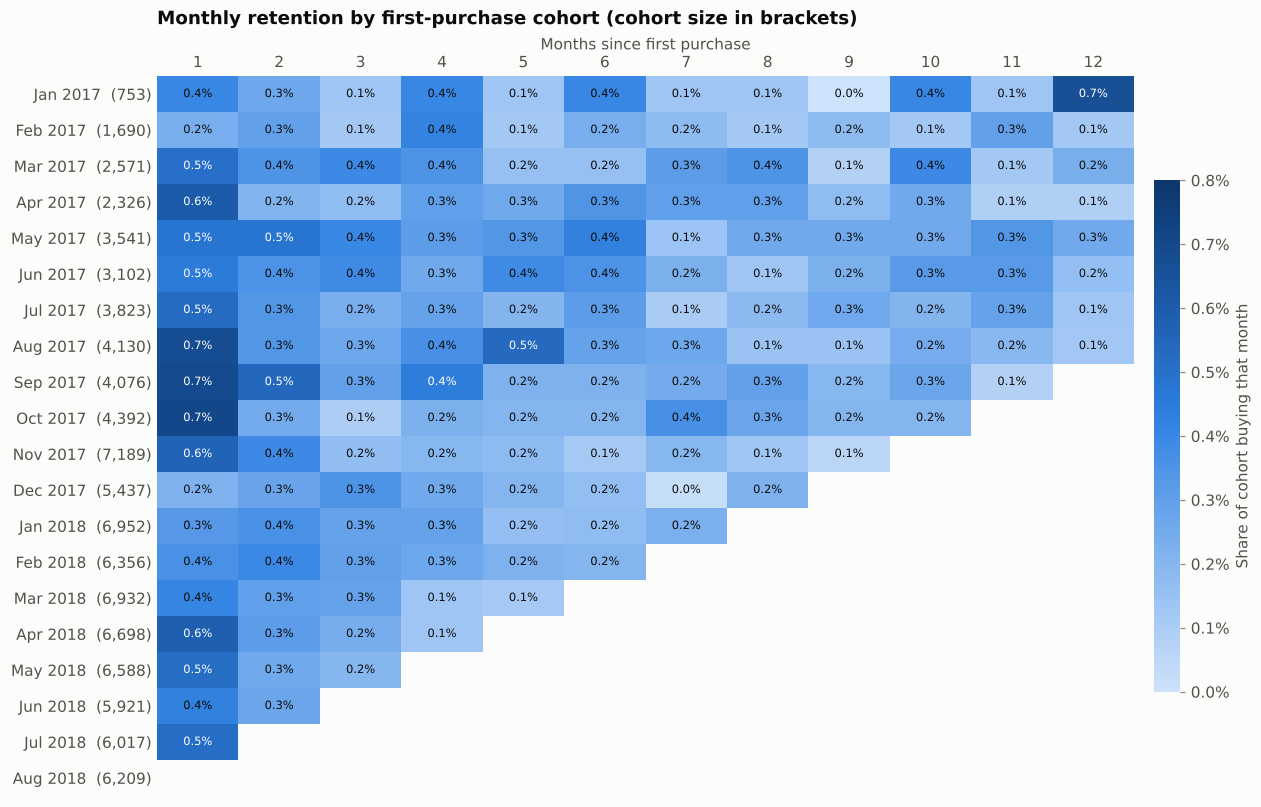

In [3]:
M = 12
view = retention.loc[:, 1:M]
vmax = 0.008

fig, ax = plt.subplots(figsize=(12, 8.5))
img = ax.imshow(view.to_numpy(), cmap=ol.SEQ_CMAP, vmin=0, vmax=vmax, aspect="auto")
for i in range(view.shape[0]):
    for j in range(view.shape[1]):
        v = view.iat[i, j]
        if np.isnan(v):
            continue
        ax.text(j, i, f"{v:.1%}", ha="center", va="center", fontsize=7.5,
                color="white" if v > vmax * 0.55 else ol.INK)
ax.set_xticks(range(M), [str(k) for k in range(1, M + 1)])
ax.set_yticks(range(len(view)), [f"{p.strftime('%b %Y')}  ({size[p]:,})" for p in view.index])
ax.xaxis.tick_top()
ax.xaxis.set_label_position("top")
ax.set_xlabel("Months since first purchase")
ax.tick_params(length=0)
ax.grid(False)
for sp in ax.spines.values():
    sp.set_visible(False)
cbar = fig.colorbar(img, ax=ax, fraction=0.025, pad=0.02, format=lambda v, _: f"{v:.1%}")
cbar.outline.set_visible(False)
cbar.set_label("Share of cohort buying that month", color=ol.INK_2)
ax.set_title("Monthly retention by first-purchase cohort (cohort size in brackets)", pad=34)
ol.save(fig, "03_retention_heatmap")
plt.show()

Note the colour scale: it tops out at 0.8%. In a typical e-commerce cohort chart month 1 sits somewhere around 10% to 30%. Here it is usually under 0.6%, and later months under 0.4%. There is no cohort, season or month where Olist kept customers well; the problem is structural, not a bad patch.

## 2. How long does a second purchase take?

Customers who came back: 2,053 (2.17%)
Days to second purchase: median 74, quartiles 22 and 174


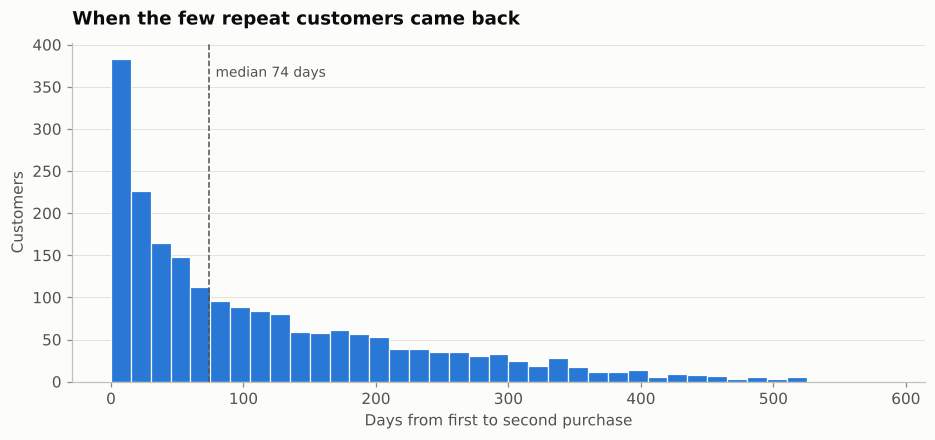

,share of repeaters
within 30 days,30%
within 90 days,55%
within 180 days,76%
within 365 days,96%


In [4]:
rep = cust[cust["repeat_ever"] == 1]
d = rep["days_to_second"]
print(f"Customers who came back: {len(rep):,} ({cust['repeat_ever'].mean():.2%})")
print(f"Days to second purchase: median {d.median():.0f}, quartiles {d.quantile(0.25):.0f} and {d.quantile(0.75):.0f}")

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(d, bins=np.arange(0, 600, 15), color=ol.SERIES[0], edgecolor=ol.SURFACE, linewidth=0.8)
ax.axvline(d.median(), color=ol.INK_2, linewidth=1, linestyle="--")
ax.text(d.median() + 5, ax.get_ylim()[1] * 0.9, f"median {d.median():.0f} days", fontsize=9, color=ol.INK_2)
ax.set_xlabel("Days from first to second purchase")
ax.set_ylabel("Customers")
ax.grid(axis="x", visible=False)
ax.set_title("When the few repeat customers came back")
ol.save(fig, "03_days_to_second")
plt.show()

shares = {f"within {w} days": (d <= w).mean() for w in (30, 90, 180, 365)}
pd.Series(shares).map("{:.0%}".format).to_frame("share of repeaters")

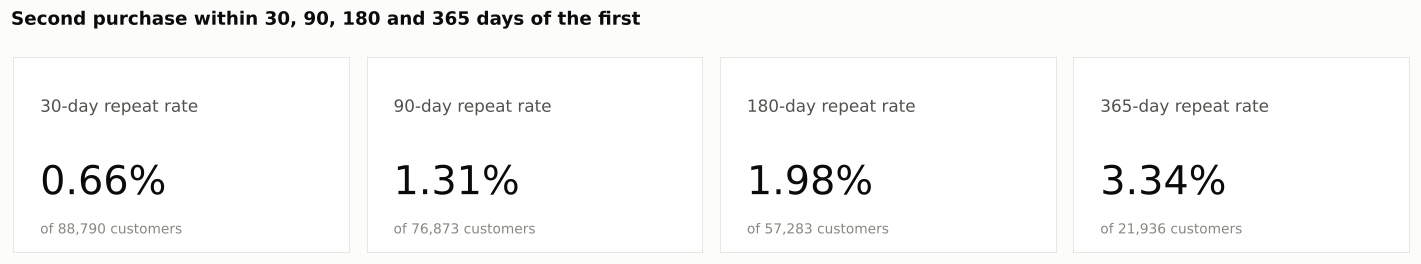

In [5]:
def repeat_within(days):
    eligible = cust[cust["first_purchase"] < ol.SNAPSHOT_END - pd.Timedelta(days=days)]
    return eligible["days_to_second"].le(days).mean(), len(eligible)


bench = {w: repeat_within(w) for w in (30, 90, 180, 365)}

fig, axes = plt.subplots(1, 4, figsize=(13, 2.4))
for ax, (w, (rate, n)) in zip(axes, bench.items()):
    ax.set_axis_off()
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, facecolor="white", edgecolor=ol.GRID))
    ax.text(0.08, 0.72, f"{w}-day repeat rate", fontsize=11, color=ol.INK_2, transform=ax.transAxes)
    ax.text(0.08, 0.30, f"{rate:.2%}", fontsize=26, color=ol.INK, transform=ax.transAxes)
    ax.text(0.08, 0.10, f"of {n:,} customers", fontsize=9, color=ol.MUTED, transform=ax.transAxes)
fig.suptitle("Second purchase within 30, 90, 180 and 365 days of the first", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
fig.tight_layout()
ol.save(fig, "03_repeat_kpis")
plt.show()

Each rate only counts customers whose first purchase was at least that many days before the snapshot, so nobody is marked as "not back" before they had the chance.

Half of the customers who return do so within about two and a half months, but the tail is long: a quarter take more than seven months. The 180-day rate (about 2%) is the target for the model in notebook 04. It captures most returns and still leaves about 57,000 customers with a full window to learn from.

## 3. What in the first order goes with coming back?

Each chart shows the 180-day repeat rate for one feature of the first order, with its 95% interval. The dashed line is the overall rate. Only customers with a full 180-day window are counted.

Customers with a full 180-day window: 57,283; overall 180-day repeat rate 1.98%


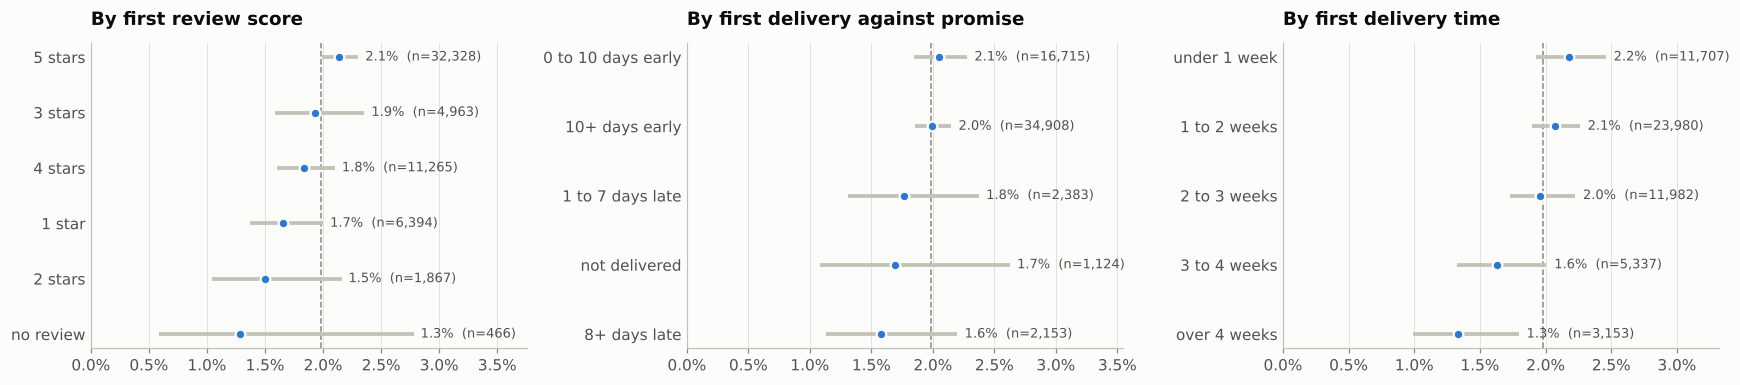

In [6]:
obs = cust[cust["repeat_180d_observed"] == 1].copy()
base = obs["repeat_180d"].mean()
print(f"Customers with a full 180-day window: {len(obs):,}; overall 180-day repeat rate {base:.2%}")

obs["review"] = obs["first_review_score"].map(lambda s: "no review" if pd.isna(s) else "1 star" if s == 1 else f"{int(s)} stars")
obs["delivery"] = pd.cut(obs["first_delay_days"], [-1000, -10, 0, 7, 1000],
                         labels=["10+ days early", "0 to 10 days early", "1 to 7 days late", "8+ days late"])
obs["delivery"] = obs["delivery"].cat.add_categories("not delivered").fillna("not delivered")
obs["speed"] = pd.cut(obs["first_delivery_days"], [0, 7, 14, 21, 30, 1000],
                      labels=["under 1 week", "1 to 2 weeks", "2 to 3 weeks", "3 to 4 weeks", "over 4 weeks"])

fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
ol.rate_chart(axes[0], ol.rate_table(obs, "review", "repeat_180d"), "By first review score", base)
ol.rate_chart(axes[1], ol.rate_table(obs, "delivery", "repeat_180d"), "By first delivery against promise", base)
ol.rate_chart(axes[2], ol.rate_table(obs, "speed", "repeat_180d"), "By first delivery time", base)
fig.tight_layout()
ol.save(fig, "03_repeat_by_experience")
plt.show()

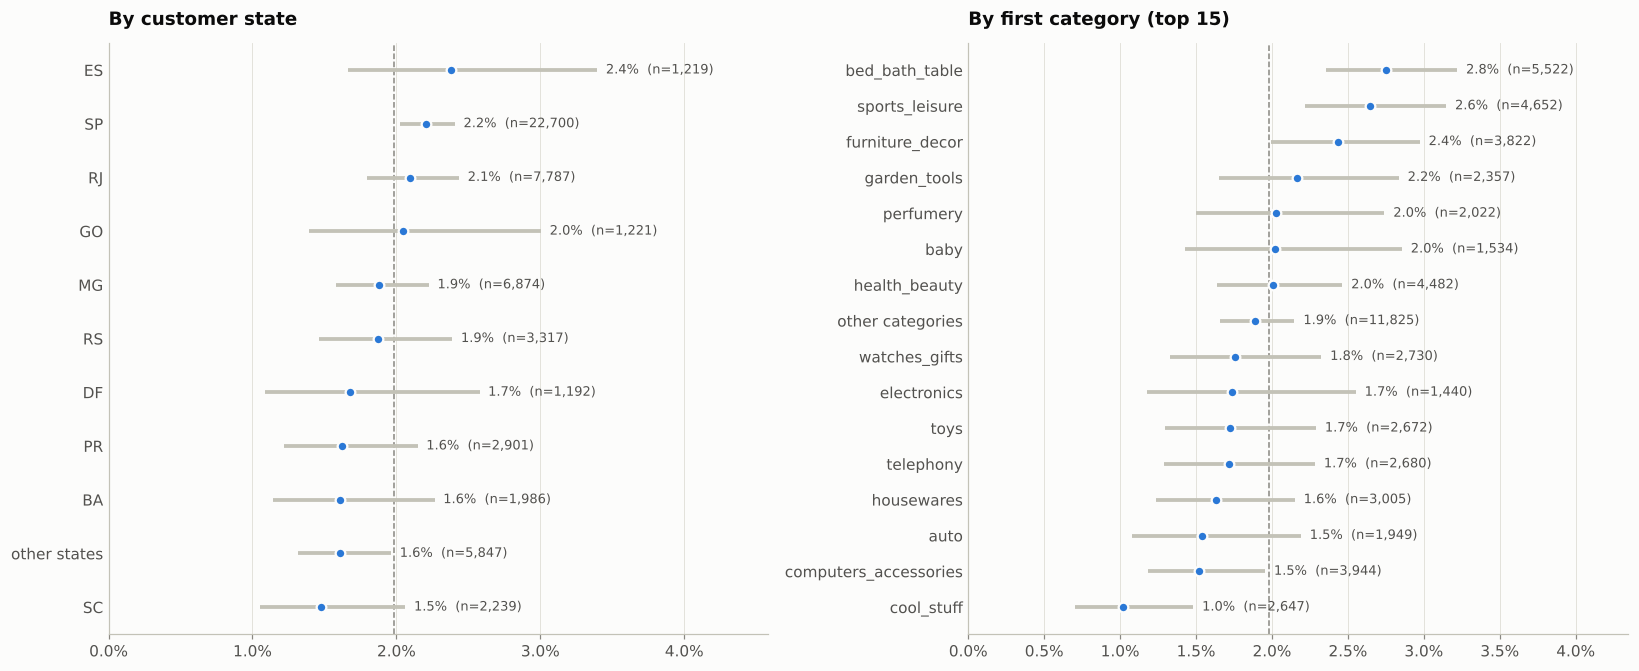

In [7]:
top_states = obs["customer_state"].value_counts().head(10).index
obs["state"] = np.where(obs["customer_state"].isin(top_states), obs["customer_state"], "other states")
top_cats = obs["first_lead_category"].value_counts().head(15).index
obs["category"] = np.where(obs["first_lead_category"].isin(top_cats), obs["first_lead_category"], "other categories")

fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))
ol.rate_chart(axes[0], ol.rate_table(obs, "state", "repeat_180d"), "By customer state", base)
ol.rate_chart(axes[1], ol.rate_table(obs, "category", "repeat_180d"), "By first category (top 15)", base)
fig.tight_layout()
ol.save(fig, "03_repeat_by_state_category")
plt.show()

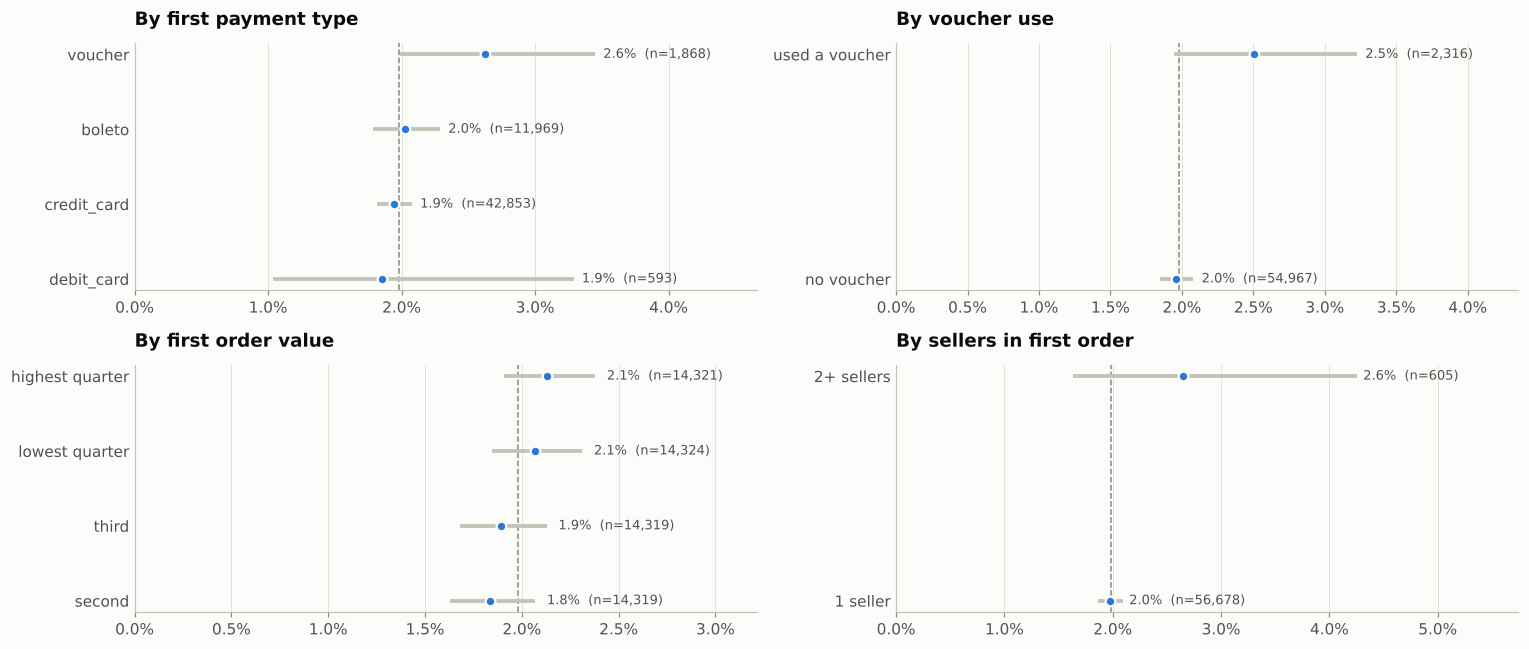

In [8]:
obs["payment"] = obs["first_payment_type"]
obs["voucher"] = obs["first_used_voucher"].map({0: "no voucher", 1: "used a voucher"})
obs["value_band"] = pd.qcut(obs["first_order_value"], 4, labels=["lowest quarter", "second", "third", "highest quarter"])
obs["sellers"] = np.where(obs["first_n_sellers"] > 1, "2+ sellers", "1 seller")

fig, axes = plt.subplots(2, 2, figsize=(14, 6))
ol.rate_chart(axes[0, 0], ol.rate_table(obs, "payment", "repeat_180d", min_n=200), "By first payment type", base)
ol.rate_chart(axes[0, 1], ol.rate_table(obs, "voucher", "repeat_180d"), "By voucher use", base)
ol.rate_chart(axes[1, 0], ol.rate_table(obs, "value_band", "repeat_180d"), "By first order value", base)
ol.rate_chart(axes[1, 1], ol.rate_table(obs, "sellers", "repeat_180d"), "By sellers in first order", base)
fig.tight_layout()
ol.save(fig, "03_repeat_by_order")
plt.show()

In [9]:
summary = []
for name, col in [("review", "review"), ("delivery against promise", "delivery"), ("delivery time", "speed"),
                  ("state", "state"), ("category", "category"), ("payment", "payment"), ("voucher", "voucher"),
                  ("order value", "value_band"), ("sellers", "sellers")]:
    t = ol.rate_table(obs, col, "repeat_180d", min_n=500)
    hi, lo = t["rate"].idxmax(), t["rate"].idxmin()
    summary.append({"feature": name, "best group": hi, "best rate": t.loc[hi, "rate"], "worst group": lo,
                    "worst rate": t.loc[lo, "rate"], "ratio": t.loc[hi, "rate"] / t.loc[lo, "rate"],
                    "intervals separate": t.loc[hi, "low"] > t.loc[lo, "high"]})
summary = pd.DataFrame(summary).sort_values("ratio", ascending=False)
summary.style.format({"best rate": "{:.2%}", "worst rate": "{:.2%}", "ratio": "{:.1f}x"})

,feature,best group,best rate,worst group,worst rate,ratio,intervals separate
4,category,bed_bath_table,2.75%,cool_stuff,1.02%,2.7x,True
2,delivery time,under 1 week,2.18%,over 4 weeks,1.33%,1.6x,True
3,state,ES,2.38%,SC,1.47%,1.6x,False
0,review,5 stars,2.14%,2 stars,1.50%,1.4x,False
5,payment,voucher,2.62%,debit_card,1.85%,1.4x,False
8,sellers,2+ sellers,2.64%,1 seller,1.97%,1.3x,False
1,delivery against promise,0 to 10 days early,2.05%,8+ days late,1.58%,1.3x,False
6,voucher,used a voucher,2.50%,no voucher,1.96%,1.3x,False
7,order value,highest quarter,2.13%,second,1.84%,1.2x,False


In [10]:
# Checks behind the notes below.
obs["review_group"] = pd.cut(obs["first_review_score"], [0, 2, 4, 5], labels=["1 or 2 stars", "3 or 4 stars", "5 stars"])
obs["in_sp"] = np.where(obs["customer_state"] == "SP", "SP", "other states")
print(ol.rate_table(obs, "review_group", "repeat_180d").round(4).to_string(), end="\n\n")
print(ol.rate_table(obs, "in_sp", "repeat_180d").round(4).to_string(), end="\n\n")
print("Inside SP, by delivery time:")
print(ol.rate_table(obs[obs["in_sp"] == "SP"], "speed", "repeat_180d").round(4).to_string(), end="\n\n")
print("Categories with 1,000+ customers, highest and lowest:")
cats = ol.rate_table(obs, "first_lead_category", "repeat_180d", min_n=1000).sort_values("rate")
print(pd.concat([cats.tail(4), cats.head(4)]).round(4).to_string())

              repeaters  customers   rate    low   high
review_group                                           
1 or 2 stars   134.0000       8261 0.0162 0.0137 0.0192
3 or 4 stars   303.0000      16228 0.0187 0.0167 0.0209
5 stars        692.0000      32328 0.0214 0.0199 0.0230

              repeaters  customers   rate    low   high
in_sp                                                  
SP             501.0000      22700 0.0221 0.0202 0.0241
other states   634.0000      34583 0.0183 0.0170 0.0198

Inside SP, by delivery time:
              repeaters  customers   rate    low   high
speed                                                  
under 1 week   194.0000       8675 0.0224 0.0195 0.0257
1 to 2 weeks   219.0000       9825 0.0223 0.0196 0.0254
2 to 3 weeks    57.0000       2600 0.0219 0.0170 0.0283
3 to 4 weeks    20.0000        816 0.0245 0.0159 0.0376
over 4 weeks     4.0000        381 0.0105 0.0041 0.0267

Categories with 1,000+ customers, highest and lowest:
                  

The table ranks each feature by the gap between its best and worst group (groups of 500+ customers), and says whether their 95% intervals separate.

Read together, the charts say something blunt: nothing in the first order moves the repeat rate much. The best groups reach about 2.5% to 3%, against 2% overall.

1. Category has the widest real gap. First orders in bed, bath and table, sports and leisure, furniture and decor, and fashion bags come back at 2.4% to 3.2%, against about 1.0% to 1.5% for cool stuff, computer accessories and auto. Home goods and personal items get bought again; gadgets and car parts are one-off needs.
2. Delivery time matters, but mostly as geography. First parcels that arrived within a week come back at 2.2%; those that took over four weeks, 1.3%. Inside São Paulo state, though, the rate is flat at about 2.2% across delivery times. The slow parcels are mostly going to distant states, where customers return less for many reasons, not only the wait.
3. Reviews show a small real gap. Customers who gave 5 stars come back at 2.1%, those who gave 1 or 2 stars at 1.6%, and the intervals just separate. Notebook 02 showed that lateness wrecks reviews; here the knock-on effect on repeat buying is real but modest.
4. Late delivery against the promise, payment type, vouchers, order value and number of sellers all show gaps whose intervals overlap. On this data they can't be told apart from noise.

## 4. Value by cohort

Spend per customer in the first six months after first purchase (months 0 to 5), for cohorts old enough to have six months of history. With so few repeat purchases this is close to the first order's value, so the chart mostly shows how basket size moved over time.

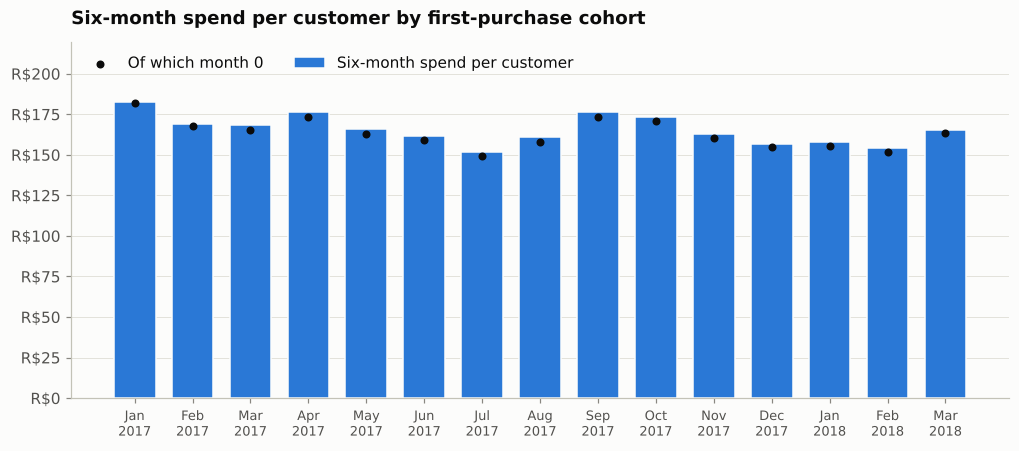

Share of six-month spend that comes after the first month: 1.5%


In [11]:
rev = done.groupby(["cohort", "k"])["order_value"].sum().unstack(fill_value=0)
cum = rev.cumsum(axis=1).div(size, axis=0)
for c in cum.index:
    cum.loc[c, cum.columns > (last_month - c).n] = np.nan
ltv6 = cum[5].dropna()
first_only = done[done["k"] == 0].groupby("cohort")["order_value"].sum() / size

fig, ax = plt.subplots(figsize=(11, 4.2))
x = np.arange(len(ltv6))
ax.bar(x, ltv6.values, color=ol.SERIES[0], width=0.72, edgecolor=ol.SURFACE, label="Six-month spend per customer")
ax.scatter(x, first_only.loc[ltv6.index].values, color=ol.INK, s=18, zorder=3, label="Of which month 0")
ax.set_xticks(x, [p.strftime("%b\n%Y") for p in ltv6.index], fontsize=8.5)
ax.grid(axis="x", visible=False)
ol.brl_axis(ax)
ax.set_ylim(0, ltv6.max() * 1.2)
ax.legend(loc="upper left", ncols=2)
ax.set_title("Six-month spend per customer by first-purchase cohort")
ol.save(fig, "03_value_by_cohort")
plt.show()

share_after = 1 - first_only.loc[ltv6.index].sum() / ltv6.sum()
print(f"Share of six-month spend that comes after the first month: {share_after:.1%}")

## 5. Export

In [12]:
out = (retention.stack(future_stack=True).rename("retention_rate").to_frame()
       .join(active.stack().rename("active_customers"))
       .join(cum.stack(future_stack=True).rename("cumulative_spend_per_customer_brl")))
out = out.reset_index().rename(columns={"k": "months_since_first_purchase", "cohort": "cohort_month"})
out = out[out["retention_rate"].notna()]
out["active_customers"] = out["active_customers"].fillna(0).astype(int)
out["cohort_size"] = out["cohort_month"].map(size)
out["cohort_month"] = out["cohort_month"].dt.strftime("%Y-%m")
out = out[["cohort_month", "cohort_size", "months_since_first_purchase", "active_customers", "retention_rate",
           "cumulative_spend_per_customer_brl"]]
out.to_csv(ol.PROCESSED / "cohort_retention.csv", index=False)
print(f"Wrote {len(out):,} rows to data/processed/cohort_retention.csv")

Wrote 208 rows to data/processed/cohort_retention.csv


## Findings

1. Olist barely keeps anyone. In every cohort, under 1% of customers buy again in any month after the first. 1.98% come back within 180 days and about 2.2% ever do. No cohort or season breaks the pattern, so the cause is structural: shoppers buy from a shop on a marketplace, and have no relationship with Olist to come back to.
2. Those who do return take their time. The median gap is 74 days; 30% return within a month, but a quarter take more than six months. A retention programme needs to stay in touch for months, not weeks.
3. The first order's category is the strongest signal. Bed, bath and table, sports and leisure, furniture and decor and fashion bags return at up to 2.7 times the rate of cool stuff, computer accessories and auto. These are the categories worth a follow-up offer.
4. Customers in São Paulo state return more often (2.2% against 1.8% elsewhere) and get faster delivery. The delivery-speed effect largely disappears inside SP, so geography explains most of it.
5. Bad experiences hurt reviews far more than they hurt repeat buying. 5-star customers return at 2.1%, 1 and 2-star customers at 1.6%. Fixing late delivery protects Olist's ratings on the marketplaces; on its own it won't fix retention.
6. Almost all of a customer's value is the first order: only 1.5% of six-month spend comes after the first month. Any lift in repeat buying is pure upside, which notebook 05 puts a number on.